<a href="https://colab.research.google.com/github/siojzz/UTSDEEPLEARNING/blob/task2-eksplorasi/kode/task2_rul/task2_eksplorasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2 — Prediksi Sisa Umur Pakai (RUL) Mesin Press: Eksplorasi, Label, Jendela Geser, dan Baseline

**Ruang lingkup tahap ini.** Notebook ini menjawab butir (a) eksplorasi dan prasyarat data, (b) pembuatan label RUL, (c) pembuatan jendela geser tanpa kebocoran informasi masa depan, serta bagian *baseline non-deep-learning* dari butir (d) dan validasi per mesin dari butir (e). Model sekuens (LSTM/GRU, CNN 1D/TCN), interval prediksi (butir f), dan model final dikerjakan pada notebook berikutnya.

**Masalah.** Untuk tiap mesin uji, diprediksi sisa siklus sebelum rusak pada siklus terakhir yang tercatat. Label RUL dibatasi pada 150 siklus. Penilaian memakai RMSE dan skor asimetris, dengan d = prediksi − aktual:

`s = Σ (exp(−d/13) − 1) bila d < 0; s = Σ (exp(d/10) − 1) bila d ≥ 0`

Prediksi yang terlalu besar (d > 0, terlalu optimistis) dihukum lebih berat daripada prediksi yang terlalu kecil, sehingga bias prediksi dilaporkan secara terpisah dari RMSE.

**Prinsip yang dijaga.**
- Validasi dipisah per mesin (*GroupKFold* menurut `id_unit`), bukan per baris, karena baris dari satu mesin berkorelasi kuat.
- Semua pembersihan data bersifat kausal: nilai pada siklus t hanya dihitung dari siklus ≤ t.
- Statistik normalisasi hanya dihitung dari data latih.

**Alur.** 0 Persiapan → 1 Data dan label → 2 Eksplorasi → 3 Normalisasi dan pembersihan → 4 Jendela geser → 5 Baseline dengan validasi per mesin → 6 Prediksi cadangan → 7 Kesimpulan → 8 Penyimpanan hasil.

## 0. Persiapan lingkungan dan data

Tahap ini memakai model non-deep-learning sehingga cukup dijalankan di CPU. Sel pertama berisi identitas akun GitHub pemilik pekerjaan ini; isi sesuai akun masing-masing sebelum menjalankan.

In [6]:
# Identitas GitHub pemilik notebook ini (untuk clone fork dan commit)
AKUN_GITHUB = 'siojzz'
EMAIL_GITHUB = 'sfyrian21@gmail.com'

import numpy, pandas, sklearn, sys, warnings
warnings.filterwarnings('ignore')
print("Python", sys.version.split()[0], "| numpy", numpy.__version__, "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1


In [7]:
# Data: unduh dari folder dosen (tanpa mount Drive)
import os
if not os.path.exists('/content/data/rul_train.csv.gz'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
!ls /content/data

clustering_meta.csv  klasifikasi_test_meta.csv	 klasifikasi_train.npz
clustering.npz	     klasifikasi_test.npz	 rul_test.csv.gz
kamus_data.md	     klasifikasi_train_meta.csv  rul_train.csv.gz


In [8]:
# Repo: clone fork, ambil main terbaru dari repo kelompok, buat branch kerja
from google.colab import userdata
import os
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/{AKUN_GITHUB}/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "{AKUN_GITHUB}"
!git config user.email "{EMAIL_GITHUB}"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git pull --no-edit upstream main
!git checkout -B task2-eksplorasi
!mkdir -p kode/task2_rul/hasil
!ls kode

/content/UTSDEEPLEARNING
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
Already up to date.
Reset branch 'task2-eksplorasi'
README.md  task1_klasifikasi  task2_rul


### Kode pendukung: `rul_data.py`

Fungsi-fungsi utama disimpan sebagai berkas Python di `kode/task2_rul/` agar tercatat di repositori dan dapat dipakai ulang oleh notebook model sekuens.

| Fungsi | Isi |
|---|---|
| `add_rul` | label RUL dari riwayat sampai rusak, dibatasi 150 |
| `skor_asimetris`, `metrik`, `metrik_per_rentang` | RMSE, skor asimetris, dan bias, keseluruhan maupun per rentang RUL |
| `pilih_k_regime`, `Normalisasi` | normalisasi yang memperhitungkan pengaturan operasi (per regime atau residu regresi) |
| `despike`, `isi_kausal` | penanganan lonjakan dan nilai hilang secara kausal (hanya memakai masa lalu) |
| `tren_per_sensor` | seleksi sensor tanpa label berdasarkan tren terhadap umur pakai |
| `fitur_jendela` | fitur statistik jendela untuk baseline non-deep-learning |
| `buat_jendela` | jendela geser tiga dimensi untuk model sekuens |

In [9]:
%%writefile /content/UTSDEEPLEARNING/kode/task2_rul/rul_data.py
import numpy as np, pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SENS = [f's{i:02d}' for i in range(1, 22)]
SET = ['setel_1', 'setel_2', 'setel_3']
CAP = 150
BINS = [(0, 30), (30, 60), (60, 100), (100, 150), (150, 10**6)]       # [a, b)
BIN_NAMES = ['0-29', '30-59', '60-99', '100-149', '150 (batas atas)']

def load(data_dir='/content/data'):
    tr = pd.read_csv(f'{data_dir}/rul_train.csv.gz')
    te = pd.read_csv(f'{data_dir}/rul_test.csv.gz')
    tr = tr.sort_values(['id_unit', 'siklus']).reset_index(drop=True)
    te = te.sort_values(['id_unit', 'siklus']).reset_index(drop=True)
    return tr, te

def add_rul(df, cap=CAP):
    """Label RUL data latih: siklus terakhir tiap mesin = siklus rusak (RUL 0), dipotong pada cap."""
    T = df.groupby('id_unit')['siklus'].transform('max')
    df = df.copy()
    df['rul_mentah'] = T - df['siklus']
    df['rul'] = df['rul_mentah'].clip(upper=cap)
    return df

# ---------- metrik ----------
def skor_asimetris(d):
    d = np.asarray(d, float)
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)      # d = prediksi - aktual

def metrik(y, p):
    d = np.asarray(p, float) - np.asarray(y, float)
    s = skor_asimetris(d)
    return dict(rmse=float(np.sqrt(np.mean(d ** 2))), skor_total=float(s.sum()),
                skor_rata=float(s.mean()), bias=float(d.mean()), n=int(len(d)))

def metrik_per_rentang(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    rows = []
    for (a, b), nm in zip(BINS, BIN_NAMES):
        m = (y >= a) & (y < b)
        if m.sum() == 0:
            continue
        r = metrik(y[m], p[m]); r['rentang'] = nm
        rows.append(r)
    return pd.DataFrame(rows).set_index('rentang')

# ---------- normalisasi bergantung kondisi operasi ----------
def _mad(v):
    v = v[~np.isnan(v)]
    if len(v) == 0:
        return 1.0
    s = 1.4826 * np.median(np.abs(v - np.median(v)))
    return s if s > 1e-12 else 1.0

def pilih_k_regime(df, kmax=8, n_sampel=6000, seed=0):
    Z = StandardScaler().fit_transform(df[SET].values)
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(Z), size=min(n_sampel, len(Z)), replace=False)
    hasil = {}
    for k in range(2, kmax + 1):
        lab = KMeans(k, n_init=5, random_state=seed).fit_predict(Z[idx])
        hasil[k] = float(silhouette_score(Z[idx], lab))
    return hasil

class Normalisasi:
    """mode='regime': z-score robust per regime operasi (klaster pada setel_1..3).
       mode='regresi': residu regresi linear sensor terhadap setel_1..3, lalu z-score."""
    def __init__(self, mode, k=None, seed=0):
        self.mode, self.k, self.seed = mode, k, seed

    def fit(self, df, cols):
        self.cols = list(cols)
        if self.mode == 'regime':
            self.sc = StandardScaler().fit(df[SET].values)
            self.km = KMeans(self.k, n_init=10, random_state=self.seed).fit(self.sc.transform(df[SET].values))
            r = self.km.predict(self.sc.transform(df[SET].values))
            g = df[self.cols].groupby(r)
            self.mu = g.median()
            self.sd = g.agg(lambda s: _mad(s.values))
        else:
            self.lr = {}
            for c in self.cols:
                m = df[c].notna().values
                X = np.c_[np.ones(m.sum()), df.loc[m, SET].values]
                coef = np.linalg.lstsq(X, df.loc[m, c].values, rcond=None)[0]
                self.lr[c] = (coef, _mad(df.loc[m, c].values - X @ coef))
        return self

    def regime(self, df):
        return self.km.predict(self.sc.transform(df[SET].values))

    def transform(self, df):
        out = df.copy()
        if self.mode == 'regime':
            r = self.regime(df)
            out[self.cols] = (df[self.cols].values - self.mu.loc[r].values) / self.sd.loc[r].values
            out['regime'] = r
        else:
            X = np.c_[np.ones(len(df)), df[SET].values]
            for c in self.cols:
                coef, s = self.lr[c]
                out[c] = (df[c].values - X @ coef) / s
        return out

# ---------- pembersihan kausal ----------
def despike(df, cols, w=5, k=6.0, scale=None):
    """Lonjakan = selisih terhadap median w siklus SEBELUMNYA > k x skala robust. Hanya memakai masa lalu."""
    prev_med = df.groupby('id_unit')[cols].transform(lambda s: s.shift(1).rolling(w, min_periods=1).median())
    res = df[cols] - prev_med
    if scale is None:
        scale = 1.4826 * (res - res.median()).abs().median()
        scale = scale.where(scale > 1e-12, 1.0)
    flag = res.abs() > k * scale
    out = df.copy()
    out[cols] = df[cols].where(~flag, prev_med)
    return out, flag.sum(), scale

def isi_kausal(df, cols):
    """Isi nilai hilang dengan nilai terakhir yang ada pada mesin yang sama; sisa (awal riwayat) = 0 (rata-rata regime)."""
    out = df.copy()
    out[cols] = out.groupby('id_unit')[cols].ffill().fillna(0.0)
    return out

def tren_per_sensor(df, cols):
    """Median korelasi Spearman nilai sensor vs nomor siklus per mesin (tanpa label, tanpa data uji)."""
    r = df.groupby('id_unit').apply(lambda g: g[cols].corrwith(g['siklus'], method='spearman'))
    return r.median()

# ---------- fitur jendela (baseline non-DL) ----------
def fitur_jendela(df, cols, W=30):
    g = df.groupby('id_unit')
    X = pd.DataFrame(index=df.index)
    X['siklus'] = df['siklus'].values
    for c in SET:
        X[c] = df[c].values
    for c in cols:
        s = g[c]
        X[c + '_last'] = df[c].values
        X[c + '_mean'] = s.transform(lambda v: v.rolling(W, min_periods=1).mean()).values
        X[c + '_std'] = s.transform(lambda v: v.rolling(W, min_periods=2).std()).fillna(0.0).values
        awal = s.shift(W - 1).fillna(s.transform('first'))
        X[c + '_diff'] = (df[c] - awal).values
    return X

# ---------- jendela geser untuk model sekuens ----------
def buat_jendela(df, cols, W=30):
    """Jendela W siklus yang berakhir di tiap siklus. Awal riwayat diisi dengan baris pertama mesin itu
    (masa lalu, bukan masa depan) dan ditandai kanal mask (0 = isian). Mengembalikan X (N, W, F+1), y, id, siklus."""
    Xs, ys, us, ts = [], [], [], []
    for u, g in df.groupby('id_unit', sort=False):
        a = g[cols].values.astype(np.float32)
        n = len(a)
        pad = np.vstack([np.repeat(a[:1], W - 1, axis=0), a]) if W > 1 else a
        mask = np.r_[np.zeros(W - 1, np.float32), np.ones(n, np.float32)]
        idx = np.arange(n)[:, None] + np.arange(W)[None, :]
        Xs.append(np.concatenate([pad[idx], mask[idx][..., None]], axis=-1))
        ys.append(g['rul'].values.astype(np.float32) if 'rul' in g.columns else np.full(n, np.nan, np.float32))
        us.append(np.full(n, u)); ts.append(g['siklus'].values)
    return np.concatenate(Xs), np.concatenate(ys), np.concatenate(us), np.concatenate(ts)


Overwriting /content/UTSDEEPLEARNING/kode/task2_rul/rul_data.py


## 1. Data dan label RUL

Data latih berisi riwayat tiap mesin sampai rusak, sehingga siklus terakhir tiap mesin adalah siklus rusak dan RUL-nya 0. Label dihitung sendiri sebagai (siklus terakhir − siklus saat ini), lalu dibatasi pada 150. Data uji berhenti pada titik acak sebelum rusak, dan prediksi diminta pada siklus terakhir tiap mesin uji.

Dua hal diperiksa sebelum memodelkan: apakah nomor siklus berurutan tanpa celah (agar jendela geser bermakna), dan seberapa mirip sebaran titik potong data uji dengan umur mesin latih.

data latih: (254174, 28) | 900 mesin | umur (siklus): min 133, median 265, maks 778
data uji  : (51692, 26) | 300 mesin | siklus terakhir: min 50, median 162, maks 455
proporsi selisih siklus = 1 pada data latih: 1.0000 | irisan id mesin latih-uji: 0
baris latih berlabel RUL = 150 (batas atas): 46.9%


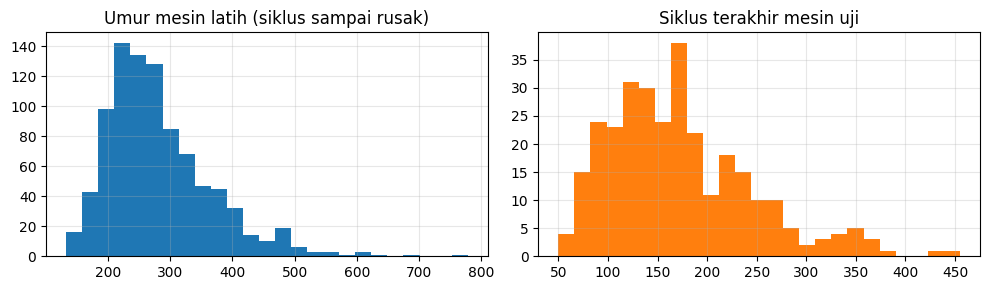

,id_unit,siklus,setel_1,setel_2,setel_3,s01,s02,s03,s04,s05,...,s14,s15,s16,s17,s18,s19,s20,s21,rul_mentah,rul
0,3,1,20.001,0.7005,100.0,1107.746,569.289,991.700,1099.533,NaN,...,1345.634,873.087,851.099,408.142,997.673,838.331,1012.076,439.003,317,150
1,3,2,34.996,0.8424,100.0,1071.040,587.821,1013.673,NaN,157.684,...,1340.661,871.230,791.396,398.338,980.601,814.985,1108.741,412.368,316,150
2,3,3,0.001,-0.0012,100.0,1130.132,585.094,998.221,1127.436,161.918,...,1330.785,872.114,807.389,388.304,938.802,847.512,1003.616,455.443,315,150


In [10]:
import sys, json, os
sys.path.append('/content/UTSDEEPLEARNING/kode/task2_rul')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from rul_data import *

REPO = '/content/UTSDEEPLEARNING'
OUT = f'{REPO}/kode/task2_rul/hasil'
HASIL, INFO = {}, {}

tr, te = load()
assert not tr[SET].isna().any().any() and not te[SET].isna().any().any(), "setel_* mengandung NaN"
tr = add_rul(tr)

umur = tr.groupby('id_unit')['siklus'].max()
potong = te.groupby('id_unit')['siklus'].max()
urut = (tr.groupby('id_unit')['siklus'].diff().dropna() == 1).mean()
print(f"data latih: {tr.shape} | {tr['id_unit'].nunique()} mesin | umur (siklus): min {umur.min()}, median {int(umur.median())}, maks {umur.max()}")
print(f"data uji  : {te.shape} | {te['id_unit'].nunique()} mesin | siklus terakhir: min {potong.min()}, median {int(potong.median())}, maks {potong.max()}")
print(f"proporsi selisih siklus = 1 pada data latih: {urut:.4f} | irisan id mesin latih-uji: {len(set(tr['id_unit']) & set(te['id_unit']))}")
print(f"baris latih berlabel RUL = 150 (batas atas): {100*(tr['rul'] == 150).mean():.1f}%")

INFO.update(n_latih=int(tr['id_unit'].nunique()), n_uji=int(te['id_unit'].nunique()),
            umur_min=int(umur.min()), umur_median=float(umur.median()), umur_maks=int(umur.max()),
            potong_min=int(potong.min()), potong_median=float(potong.median()), potong_maks=int(potong.max()),
            persen_rul_cap=float(100 * (tr['rul'] == 150).mean()))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(umur, bins=25); ax[0].set_title('Umur mesin latih (siklus sampai rusak)')
ax[1].hist(potong, bins=25, color='C1'); ax[1].set_title('Siklus terakhir mesin uji')
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()
display(tr.head(3))

## 2. Eksplorasi: nilai hilang, pengaruh pengaturan operasi, dan regime

Tiga pemeriksaan dilakukan pada data latih:
1. **Nilai hilang** (`NaN`) per sensor pada data latih dan data uji.
2. **Pengaruh pengaturan operasi.** Setiap sensor diregresikan secara linear terhadap `setel_1`, `setel_2`, `setel_3`. Nilai R² yang tinggi berarti variasi sensor sebagian besar mencerminkan pengaturan mesin, bukan penuaan, sehingga perlu dinormalisasi.
3. **Regime operasi.** Pengaturan operasi dikelompokkan dengan *k-means* untuk k = 2 sampai 8, dan kualitas klaster dinilai dengan koefisien *silhouette*. Bila klasternya jelas (silhouette ≥ 0,6), pengaturan operasi dianggap berupa beberapa regime diskret dan sensor dinormalisasi per regime. Bila tidak, pengaturan dianggap kontinu dan pengaruhnya dihilangkan dengan regresi linear.

In [11]:
miss = pd.DataFrame({'latih (%)': 100 * tr[SENS].isna().mean(), 'uji (%)': 100 * te[SENS].isna().mean()}).round(2)
display(miss.T)
INFO['nan_latih_persen'] = float(100 * tr[SENS].isna().values.mean())
INFO['nan_uji_persen'] = float(100 * te[SENS].isna().values.mean())

def r2_setel(df, c):
    m = df[c].notna().values
    X = np.c_[np.ones(m.sum()), df.loc[m, SET].values]; v = df.loc[m, c].values
    res = v - X @ np.linalg.lstsq(X, v, rcond=None)[0]
    return 1 - res.var() / v.var() if v.var() > 0 else np.nan
r2 = pd.Series({c: r2_setel(tr, c) for c in SENS}).round(3)
print("R2 regresi sensor terhadap setel_1..3:")
display(r2.to_frame('R2').T)
INFO['r2_median'] = float(r2.median()); INFO['r2_maks'] = float(r2.max()); INFO['r2_maks_sensor'] = str(r2.idxmax())

ks = pilih_k_regime(tr)
print("silhouette k-means pada setel_1..3:", {k: round(v, 3) for k, v in ks.items()})
K = max(ks, key=ks.get)
MODE = 'regime' if ks[K] >= 0.6 else 'regresi'
print(f"keputusan: mode normalisasi = {MODE}" + (f", k = {K}" if MODE == 'regime' else ""))
INFO.update(mode_normalisasi=MODE, k_regime=int(K), silhouette_terbaik=float(ks[K]))

,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
latih (%),2.00,2.07,2.01,2.05,2.01,2.06,2.05,2.02,2.04,2.02,...,2.04,2.03,1.99,2.02,2.00,2.01,2.06,2.03,2.11,1.97
uji (%),2.01,1.95,2.04,2.09,2.02,2.02,2.00,1.95,1.98,2.14,...,1.89,1.95,1.95,1.97,1.99,2.10,1.92,2.04,1.96,2.06


R2 regresi sensor terhadap setel_1..3:


,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
R2,0.639,0.705,0.699,0.542,0.841,0.392,0.339,0.088,0.549,0.599,...,0.596,0.891,0.767,0.402,0.571,0.823,0.835,0.754,0.39,0.379


silhouette k-means pada setel_1..3: {2: 0.602, 3: 0.792, 4: 0.85, 5: 0.935, 6: 0.991, 7: 0.92, 8: 0.844}
keputusan: mode normalisasi = regime, k = 6


## 3. Normalisasi dan pembersihan kausal

Urutan pemrosesan, seluruhnya hanya memakai data latih untuk menghitung statistik:
1. **Normalisasi terhadap kondisi operasi**, sesuai keputusan pada bagian 2. Rerata dan simpangan baku dihitung dengan median dan MAD agar tidak terpengaruh lonjakan.
2. **Penanganan lonjakan (*spike*).** Sebuah bacaan dianggap lonjakan bila menyimpang dari median lima siklus sebelumnya lebih dari 6 kali skala robust, dan diganti dengan median tersebut. Hanya masa lalu yang dipakai.
3. **Nilai hilang.** Diisi dengan bacaan terakhir yang ada pada mesin yang sama; sisanya (awal riwayat) diisi 0, yaitu nilai tipikal regime setelah normalisasi.
4. **Seleksi sensor tanpa label.** Untuk tiap sensor dihitung korelasi Spearman nilai terhadap nomor siklus pada tiap mesin, lalu diambil mediannya. Sensor dengan |median| < 0,1 dianggap tidak membawa tren penuaan dan dibuang. Pemilihan ini tidak memakai label RUL, sehingga tidak membocorkan informasi ke data validasi.

lonjakan yang terdeteksi per sensor (% dari bacaan yang ada, data latih):


,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
%,0.07,0.07,0.06,0.07,0.07,0.08,0.06,0.05,0.06,0.06,...,0.07,0.07,0.07,0.07,0.08,0.06,0.08,0.08,0.08,0.07


tren (median korelasi Spearman terhadap siklus, per mesin):


,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
tren,-0.0,-0.67,-0.62,0.74,-0.0,-0.0,-0.62,0.6,0.05,-0.0,...,0.68,-0.06,-0.05,0.65,0.0,-0.06,0.0,-0.0,-0.05,-0.06


sensor dipakai (8): ['s02', 's03', 's04', 's07', 's08', 's11', 's12', 's15']
sensor dibuang (13): ['s01', 's05', 's06', 's09', 's10', 's13', 's14', 's16', 's17', 's18', 's19', 's20', 's21']


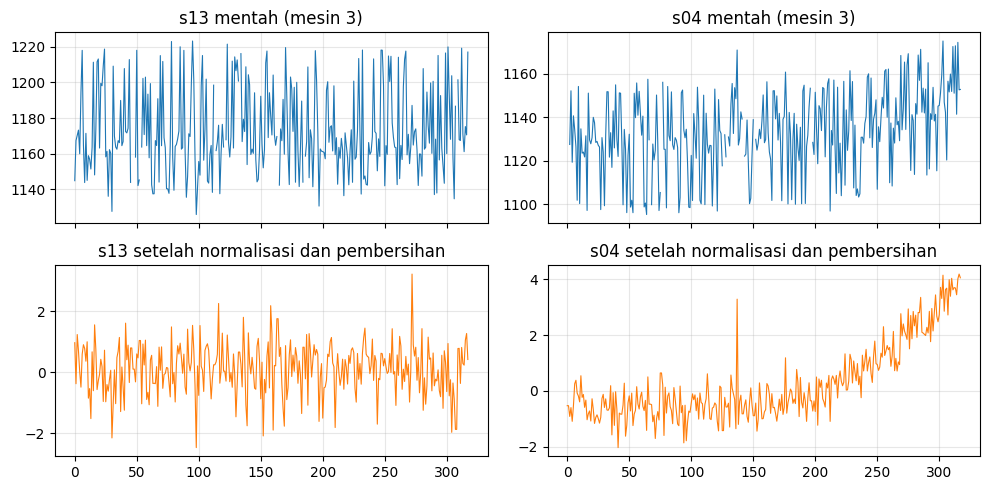

In [12]:
nm = Normalisasi(MODE, K).fit(tr, SENS)
trn, ten = nm.transform(tr), nm.transform(te)

trn, n_spike, skala = despike(trn, SENS)
ten, n_spike_te, _ = despike(ten, SENS, scale=skala)
trc, tec = isi_kausal(trn, SENS), isi_kausal(ten, SENS)

lonjakan = (100 * n_spike / tr[SENS].notna().sum()).round(2)
print("lonjakan yang terdeteksi per sensor (% dari bacaan yang ada, data latih):")
display(lonjakan.to_frame('%').T)
INFO['n_lonjakan_latih'] = int(n_spike.sum()); INFO['n_lonjakan_uji'] = int(n_spike_te.sum())

tren = tren_per_sensor(trc, SENS)
THR = 0.1
PAKAI = [c for c in SENS if abs(tren[c]) >= THR]
if len(PAKAI) < 3:
    PAKAI = list(tren.abs().sort_values(ascending=False).index[:8])
    print("peringatan: sensor yang lolos ambang terlalu sedikit; dipakai 8 sensor dengan |tren| terbesar")
print("tren (median korelasi Spearman terhadap siklus, per mesin):")
display(tren.round(2).to_frame('tren').T)
print(f"sensor dipakai ({len(PAKAI)}):", PAKAI)
print(f"sensor dibuang ({21 - len(PAKAI)}):", [c for c in SENS if c not in PAKAI])
INFO.update(sensor_dipakai=PAKAI, ambang_tren=THR)

u0 = tr['id_unit'].iloc[0]
c1, c2 = r2.idxmax(), tren.abs().idxmax()
fig, ax = plt.subplots(2, 2, figsize=(10, 5), sharex=True)
for j, c in enumerate([c1, c2]):
    ax[0, j].plot(tr.loc[tr['id_unit'] == u0, c].values, lw=.8); ax[0, j].set_title(f'{c} mentah (mesin {u0})')
    ax[1, j].plot(trc.loc[trc['id_unit'] == u0, c].values, lw=.8, color='C1'); ax[1, j].set_title(f'{c} setelah normalisasi dan pembersihan')
for a in ax.ravel(): a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Jendela geser tanpa kebocoran

Untuk model sekuens, setiap siklus menjadi satu sampel berupa jendela W = 30 siklus yang **berakhir** pada siklus itu. Riwayat yang lebih pendek dari 30 siklus (awal masa pakai) dilengkapi dengan mengulang baris pertama mesin tersebut, yaitu data masa lalu, dan ditandai dengan satu kanal *mask* (0 = isian) agar model dapat membedakannya dari data asli. Dengan cara ini mesin dengan riwayat berbeda panjang diperlakukan seragam tanpa memakai data masa depan.

Sebagai pemeriksaan, jendela pada siklus t dari riwayat yang dipotong sampai t dibandingkan dengan jendela yang sama dari riwayat lengkap. Keduanya harus identik; bila tidak, ada kebocoran informasi masa depan.

In [13]:
W = 30
Xw, yw, uw, tw = buat_jendela(trc, PAKAI, W)
print("jendela latih:", Xw.shape, "(sampel, W, sensor + mask) | label:", yw.shape)

# uji kebocoran: jendela dari riwayat terpotong harus sama dengan jendela dari riwayat lengkap
ok = []
for u in np.random.default_rng(0).choice(trc['id_unit'].unique(), 5, replace=False):
    g = trc[trc['id_unit'] == u]
    for t in (5, 20, 100):
        if len(g) > t:
            Xt, _, _, _ = buat_jendela(g.iloc[:t], PAKAI, W)
            ok.append(np.allclose(Xt[-1], Xw[uw == u][t - 1]))
print(f"uji kebocoran: {sum(ok)} dari {len(ok)} pemeriksaan identik")
assert all(ok), "ada kebocoran informasi masa depan pada jendela"

Xte_w, _, ute_w, tte_w = buat_jendela(tec, PAKAI, W)
last_idx = tec.groupby('id_unit', sort=False).tail(1).index.values
print("jendela uji pada siklus terakhir tiap mesin:", Xte_w[np.isin(np.arange(len(tec)), last_idx)].shape)
INFO['W'] = W

jendela latih: (254174, 30, 9) (sampel, W, sensor + mask) | label: (254174,)
uji kebocoran: 15 dari 15 pemeriksaan identik
jendela uji pada siklus terakhir tiap mesin: (300, 30, 9)


## 5. Baseline non-deep-learning dengan validasi per mesin

**Fitur.** Untuk tiap sensor terpilih dihitung empat fitur dari jendela 30 siklus yang berakhir di siklus saat ini: nilai terakhir, rerata, simpangan baku, dan perubahan terhadap awal jendela. Ditambahkan nomor siklus dan tiga pengaturan operasi.

**Model.** Tiga pembanding: (1) konstanta median, sebagai batas bawah yang menunjukkan nilai tanpa informasi; (2) regresi Ridge; (3) *gradient boosting* berbasis histogram.

**Validasi.** 5-fold *GroupKFold* menurut mesin, sehingga semua siklus satu mesin berada pada fold yang sama. Dua cara pengukuran dilaporkan:
- **Semua siklus:** seluruh baris validasi, dengan rincian per rentang RUL.
- **Mirip uji:** satu titik acak per mesin, diulang 20 kali dan dirata-ratakan, sesuai cara data uji dibentuk (satu prediksi pada titik acak sebelum rusak). Skor asimetris total pada pengukuran ini setara skalanya dengan penilaian uji, yaitu jumlah atas mesin.

In [14]:
from sklearn.model_selection import GroupKFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor

X = fitur_jendela(trc, PAKAI, W=W)
y = trc['rul'].values
grup = trc['id_unit'].values
print("fitur baseline:", X.shape)

MODELS = {
    'Konstanta (median)': lambda: DummyRegressor(strategy='median'),
    'Ridge': lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    'Gradient boosting (HGB)': lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0),
}

def oof_prediksi(fn, n_fold=5):
    oof = np.zeros(len(y))
    for a, b in GroupKFold(n_fold).split(X, y, grup):
        oof[b] = fn().fit(X.iloc[a], y[a]).predict(X.iloc[b])
    return np.clip(oof, 0, CAP)

def mirip_uji(oof, n_ulang=20):
    r = []
    for rep in range(n_ulang):
        idx = trc.groupby('id_unit').sample(1, random_state=rep).index
        r.append(metrik(y[idx], oof[idx]))
    return {k: float(np.mean([x[k] for x in r])) for k in ('rmse', 'skor_total', 'skor_rata', 'bias')}

OOF, PER_RENTANG = {}, {}
for nama, fn in MODELS.items():
    OOF[nama] = oof_prediksi(fn)
    a, b = metrik(y, OOF[nama]), mirip_uji(OOF[nama])
    HASIL[nama] = dict(rmse=a['rmse'], skor_rata=a['skor_rata'], bias=a['bias'],
                       rmse_miripuji=b['rmse'], skor_total_miripuji=b['skor_total'], skor_rata_miripuji=b['skor_rata'], bias_miripuji=b['bias'])
    PER_RENTANG[nama] = metrik_per_rentang(y, OOF[nama])
    print(f"{nama}: RMSE {a['rmse']:.2f} (semua siklus) | RMSE {b['rmse']:.2f}, skor total {b['skor_total']:.1f} (mirip uji)")

tab = pd.DataFrame(HASIL).T.astype(float)
tab.columns = ['RMSE', 'skor asimetris rata-rata', 'bias', 'RMSE mirip-uji', 'skor total mirip-uji', 'skor rata-rata mirip-uji', 'bias mirip-uji']
display(tab.round(3))

fitur baseline: (254174, 36)
Konstanta (median): RMSE 58.16 (semua siklus) | RMSE 60.04, skor total 46297647.6 (mirip uji)
Ridge: RMSE 22.38 (semua siklus) | RMSE 23.62, skor total 36512.5 (mirip uji)
Gradient boosting (HGB): RMSE 18.83 (semua siklus) | RMSE 19.85, skor total 24715.8 (mirip uji)


,RMSE,skor asimetris rata-rata,bias,RMSE mirip-uji,skor total mirip-uji,skor rata-rata mirip-uji,bias mirip-uji
Konstanta (median),58.160,49453.482,31.099,60.043,4.629765e+07,51441.831,34.252
Ridge,22.378,29.323,-0.065,23.624,3.651246e+04,40.569,3.233
Gradient boosting (HGB),18.825,18.763,-0.229,19.851,2.471582e+04,27.462,2.030


In [15]:
print("Rincian per rentang RUL (semua siklus validasi). Bias positif = prediksi lebih besar dari aktual (terlalu optimistis).")
gab = pd.concat({n: PER_RENTANG[n][['n', 'rmse', 'bias', 'skor_rata']] for n in MODELS}, names=['model'])
display(gab.round(3))
for n in MODELS:
    HASIL[n]['per_rentang'] = {r: {k: float(v) for k, v in row.items()} for r, row in PER_RENTANG[n].iterrows()}

Rincian per rentang RUL (semua siklus validasi). Bias positif = prediksi lebih besar dari aktual (terlalu optimistis).


n     rmse     bias   skor_rata
model                   rentang                                               
Konstanta (median)      0-29               27000  126.796  126.500  442368.993
                        30-59              27000   96.887   96.500   22023.305
                        60-99              36000   62.574   61.500     848.632
                        100-149            44932   21.936   16.529      11.738
                        150 (batas atas)  119242    9.000   -9.000       0.998
Ridge                   0-29               27000   18.680    7.551      15.476
                        30-59              27000   30.679   18.893     107.531
                        60-99              36000   33.418   21.221      92.212
                        100-149            44932   20.999    1.252       9.144
                        150 (batas atas)  119242   16.491  -13.004       3.367
Gradient boosting (HGB) 0-29               27000   12.010    6.177       3.010
                        30-59              27000   21.476    7.205      52.470
                        60-99              36000   31.048   14.083      72.423
                        100-149            44932   21.471    1.187       9.101
                        150 (batas atas)  119242   12.392   -8.218       2.139

## 6. Prediksi cadangan untuk data uji

Model baseline dengan RMSE "mirip-uji" terendah dilatih ulang pada seluruh data latih dan dipakai memprediksi RUL pada siklus terakhir tiap mesin uji. Hasilnya disimpan sebagai `prediksi_rul.csv` (kolom `id_unit`, `rul`, nilai dibatasi 0 sampai 150). Berkas ini berfungsi sebagai prediksi cadangan; akan diganti oleh model sekuens final bila lebih baik pada validasi.

In [16]:
terbaik = min(MODELS, key=lambda n: HASIL[n]['rmse_miripuji'])
model = MODELS[terbaik]().fit(X, y)
Xte = fitur_jendela(tec, PAKAI, W=W)
akhir = tec.groupby('id_unit', sort=False).tail(1).index
pred = np.clip(model.predict(Xte.loc[akhir]), 0, CAP)

sub = pd.DataFrame({'id_unit': tec.loc[akhir, 'id_unit'].values, 'rul': np.round(pred, 2)})
assert len(sub) == te['id_unit'].nunique() and sub['id_unit'].is_unique and sub['rul'].between(0, CAP).all()
assert (tec.loc[akhir, 'siklus'].values == te.groupby('id_unit')['siklus'].max().loc[sub['id_unit']].values).all()
sub.to_csv(f'{REPO}/prediksi_rul.csv', index=False)
print("model:", terbaik, "| tersimpan:", f'{REPO}/prediksi_rul.csv', "|", len(sub), "baris")
display(sub.head())
display(sub['rul'].describe().round(2).to_frame('prediksi RUL (uji)').T)
INFO['model_cadangan'] = terbaik

model: Gradient boosting (HGB) | tersimpan: /content/UTSDEEPLEARNING/prediksi_rul.csv | 300 baris


,id_unit,rul
0,1,74.94
1,2,40.23
2,6,110.95
3,8,130.77
4,16,36.29


,count,mean,std,min,25%,50%,75%,max
prediksi RUL (uji),300.0,96.4,44.51,5.17,56.95,111.7,136.48,150.0


## 7. Kesimpulan

Kesimpulan di bawah disusun otomatis dari hasil di atas, sehingga seluruh angka konsisten dengan tabel.

In [17]:
def _f(x, n=1): return f"{x:.{n}f}".replace('.', ',')

def buat_kesimpulan_t2(H, info, per_rentang):
    t = []
    t.append(f"**1. Data dan label.** Data latih memuat {info['n_latih']} mesin dengan umur {info['umur_min']}–{info['umur_maks']} siklus (median {_f(info['umur_median'], 0)}). "
             f"Data uji memuat {info['n_uji']} mesin yang berhenti pada siklus {info['potong_min']}–{info['potong_maks']} (median {_f(info['potong_median'], 0)}). "
             f"Setelah pembatasan 150 siklus, {_f(info['persen_rul_cap'])}% baris latih berlabel 150.")
    mode = (f"normalisasi per regime dengan k = {info['k_regime']} (silhouette {_f(info['silhouette_terbaik'], 2)})" if info['mode_normalisasi'] == 'regime'
            else f"regresi linear terhadap pengaturan operasi (silhouette terbaik {_f(info['silhouette_terbaik'], 2)}, di bawah ambang 0,6)")
    t.append(f"**2. Pengaturan operasi.** Regresi linear sensor terhadap `setel_1..3` menghasilkan R² median {_f(info['r2_median'], 2)} dan maksimum {_f(info['r2_maks'], 2)} (sensor {info['r2_maks_sensor']}). "
             f"Berdasarkan struktur klaster pengaturan operasi, dipakai {mode}.")
    t.append(f"**3. Kualitas data dan seleksi sensor.** Nilai hilang berjumlah {_f(info['nan_latih_persen'], 2)}% pada data latih dan {_f(info['nan_uji_persen'], 2)}% pada data uji. "
             f"Terdeteksi {info['n_lonjakan_latih']} bacaan lonjakan pada data latih. Dari 21 sensor, {len(info['sensor_dipakai'])} dipakai "
             f"(ambang |tren| ≥ {_f(info['ambang_tren'], 1)}): {', '.join(info['sensor_dipakai'])}.")
    nama = list(per_rentang)
    best = min([n for n in nama if n in H], key=lambda n: H[n]['rmse_miripuji'])
    kons = H['Konstanta (median)']
    t.append(f"**4. Baseline.** Dengan validasi per mesin, model terbaik adalah **{best}**: RMSE {_f(H[best]['rmse'], 2)} pada semua siklus dan {_f(H[best]['rmse_miripuji'], 2)} pada pengukuran mirip-uji "
             f"(skor asimetris total {_f(H[best]['skor_total_miripuji'], 1)}). Pembanding konstanta median memberi RMSE {_f(kons['rmse'], 2)} dan {_f(kons['rmse_miripuji'], 2)}, "
             f"sehingga model terbaik menurunkan RMSE mirip-uji sebesar {_f(100 * (1 - H[best]['rmse_miripuji'] / kons['rmse_miripuji']), 0)}%.")
    pr = per_rentang[best]
    terburuk = pr['rmse'].idxmax(); opt = [r for r in pr.index if pr.loc[r, 'bias'] > 0]
    t.append(f"**5. Per rentang RUL.** RMSE terbesar ada pada rentang {terburuk} ({_f(pr.loc[terburuk, 'rmse'], 2)}), terkecil pada {pr['rmse'].idxmin()} ({_f(pr['rmse'].min(), 2)}). "
             + (f"Bias positif (prediksi lebih besar dari aktual, sisi yang dihukum lebih berat) muncul pada rentang: {', '.join(opt)}." if opt else "Tidak ada rentang dengan bias positif."))
    t.append("**6. Keterbatasan.** Statistik normalisasi, ambang lonjakan, dan seleksi sensor dihitung dari seluruh data latih termasuk mesin pada fold validasi; tidak ada label yang dipakai, tetapi tetap perlu dicatat. "
             "Baseline hanya memakai fitur statistik jendela dan belum menggambarkan urutan waktu secara penuh. Model sekuens, interval prediksi, dan analisis kapan mesin sebaiknya diservis dikerjakan pada tahap berikutnya.")
    return "\n\n".join(t)

display(Markdown(buat_kesimpulan_t2(HASIL, INFO, PER_RENTANG)))

**1. Data dan label.** Data latih memuat 900 mesin dengan umur 133–778 siklus (median 265). Data uji memuat 300 mesin yang berhenti pada siklus 50–455 (median 162). Setelah pembatasan 150 siklus, 46,9% baris latih berlabel 150.

**2. Pengaturan operasi.** Regresi linear sensor terhadap `setel_1..3` menghasilkan R² median 0,60 dan maksimum 0,89 (sensor s13). Berdasarkan struktur klaster pengaturan operasi, dipakai normalisasi per regime dengan k = 6 (silhouette 0,99).

**3. Kualitas data dan seleksi sensor.** Nilai hilang berjumlah 2,03% pada data latih dan 2,00% pada data uji. Terdeteksi 3545 bacaan lonjakan pada data latih. Dari 21 sensor, 8 dipakai (ambang |tren| ≥ 0,1): s02, s03, s04, s07, s08, s11, s12, s15.

**4. Baseline.** Dengan validasi per mesin, model terbaik adalah **Gradient boosting (HGB)**: RMSE 18,83 pada semua siklus dan 19,85 pada pengukuran mirip-uji (skor asimetris total 24715,8). Pembanding konstanta median memberi RMSE 58,16 dan 60,04, sehingga model terbaik menurunkan RMSE mirip-uji sebesar 67%.

**5. Per rentang RUL.** RMSE terbesar ada pada rentang 60-99 (31,05), terkecil pada 0-29 (12,01). Bias positif (prediksi lebih besar dari aktual, sisi yang dihukum lebih berat) muncul pada rentang: 0-29, 30-59, 60-99, 100-149.

**6. Keterbatasan.** Statistik normalisasi, ambang lonjakan, dan seleksi sensor dihitung dari seluruh data latih termasuk mesin pada fold validasi; tidak ada label yang dipakai, tetapi tetap perlu dicatat. Baseline hanya memakai fitur statistik jendela dan belum menggambarkan urutan waktu secara penuh. Model sekuens, interval prediksi, dan analisis kapan mesin sebaiknya diservis dikerjakan pada tahap berikutnya.

## 8. Penyimpanan hasil

Hasil baseline dan keputusan pra-pemrosesan disimpan dalam `hasil/task2_baseline.json`. Kode di-commit ke repositori kelompok melalui branch `task2-eksplorasi`. Berkas `prediksi_rul.csv` yang dibuat di sini adalah prediksi cadangan.

In [18]:
with open(f'{OUT}/task2_baseline.json', 'w') as f:
    json.dump({'info': INFO, 'hasil': HASIL}, f, indent=2)
%cd /content/UTSDEEPLEARNING
!git add kode/task2_rul/rul_data.py kode/task2_rul/hasil/task2_baseline.json prediksi_rul.csv
!git commit -m "Task 2: eksplorasi, label RUL, jendela geser, baseline dan prediksi cadangan"
!git push origin task2-eksplorasi

/content/UTSDEEPLEARNING
[task2-eksplorasi 888c7f3] Task 2: eksplorasi, label RUL, jendela geser, baseline dan prediksi cadangan
 3 files changed, 638 insertions(+)
 create mode 100644 kode/task2_rul/hasil/task2_baseline.json
 create mode 100644 kode/task2_rul/rul_data.py
 create mode 100644 prediksi_rul.csv
Enumerating objects: 10, done.
Counting objects: 100% (10/10), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (8/8), 6.18 KiB | 6.18 MiB/s, done.
Total 8 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
remote: 
remote: Create a pull request for 'task2-eksplorasi' on GitHub by visiting:
remote:      https://github.com/siojzz/UTSDEEPLEARNING/pull/new/task2-eksplorasi
remote: 
To https://github.com/siojzz/UTSDEEPLEARNING.git
 * [new branch]      task2-eksplorasi -> task2-eksplorasi
